# Flower Recognition

Sondos Mohamed Mohamed Abd Elmoniem Gafar


2022/02126

## Importing Libraries

In [86]:
import numpy as np
import pandas as pd
from pathlib import Path
import os.path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import matplotlib.cm as cm

import tensorflow as tf 
import requests
from PIL import Image
from io import BytesIO
import os
import shutil
from tqdm import tqdm
from random import shuffle

import cv2
from glob import glob

from tensorflow.keras import backend as K
import random
import albumentations as A
from sklearn.model_selection import train_test_split, StratifiedKFold

from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import *
from tensorflow.keras.models import *
from tensorflow.keras.preprocessing.image import *
from tensorflow.keras.callbacks import *
from tensorflow.keras.applications.efficientnet import *
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings("ignore")

In [ ]:
image_dir = Path("./flowers")

filepaths = list(image_dir.glob(r'**/*.jpg'))

labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1], filepaths))

filepaths = pd.Series(filepaths, name='Filepath').astype(str)
labels = pd.Series(labels, name='Label')

image_df = pd.concat([filepaths, labels], axis=1)

## Viewing Dataset

In [17]:

image_df.head()


,Filepath,Label
0,flowers\daisy\100080576_f52e8ee070_n.jpg,daisy
1,flowers\daisy\10140303196_b88d3d6cec.jpg,daisy
2,flowers\daisy\10172379554_b296050f82_n.jpg,daisy
3,flowers\daisy\10172567486_2748826a8b.jpg,daisy
4,flowers\daisy\10172636503_21bededa75_n.jpg,daisy


In [18]:

image_df.tail()

,Filepath,Label
4312,flowers\tulip\9831362123_5aac525a99_n.jpg,tulip
4313,flowers\tulip\9870557734_88eb3b9e3b_n.jpg,tulip
4314,flowers\tulip\9947374414_fdf1d0861c_n.jpg,tulip
4315,flowers\tulip\9947385346_3a8cacea02_n.jpg,tulip
4316,flowers\tulip\9976515506_d496c5e72c.jpg,tulip


In [19]:
image_df.isnull().sum()


Filepath    0
Label       0
dtype: int64

In [6]:
image_df = image_df.sample(frac=1).reset_index(drop = True)
image_df.head(5)

,Filepath,Label
0,flowers\tulip\32465197894_71dde519ae_n.jpg,tulip
1,flowers\daisy\4258408909_b7cc92741c_m.jpg,daisy
2,flowers\daisy\33814092924_b23d019011_n.jpg,daisy
3,flowers\tulip\7205698252_b972087cc2.jpg,tulip
4,flowers\tulip\13979840624_28466cb3ec_n.jpg,tulip


###  *Shape of Dataset*

In [20]:
image_df.shape

(4317, 2)

## *Visualizations of Dataset (EDA)*

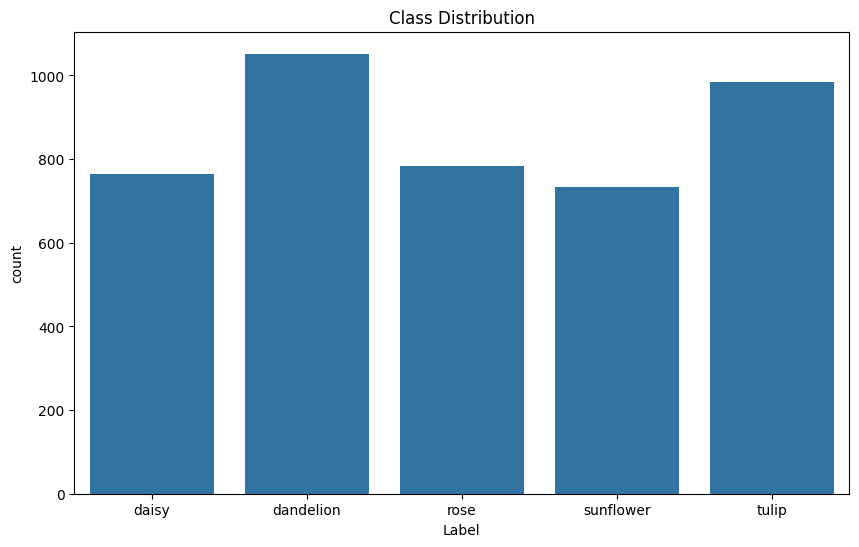

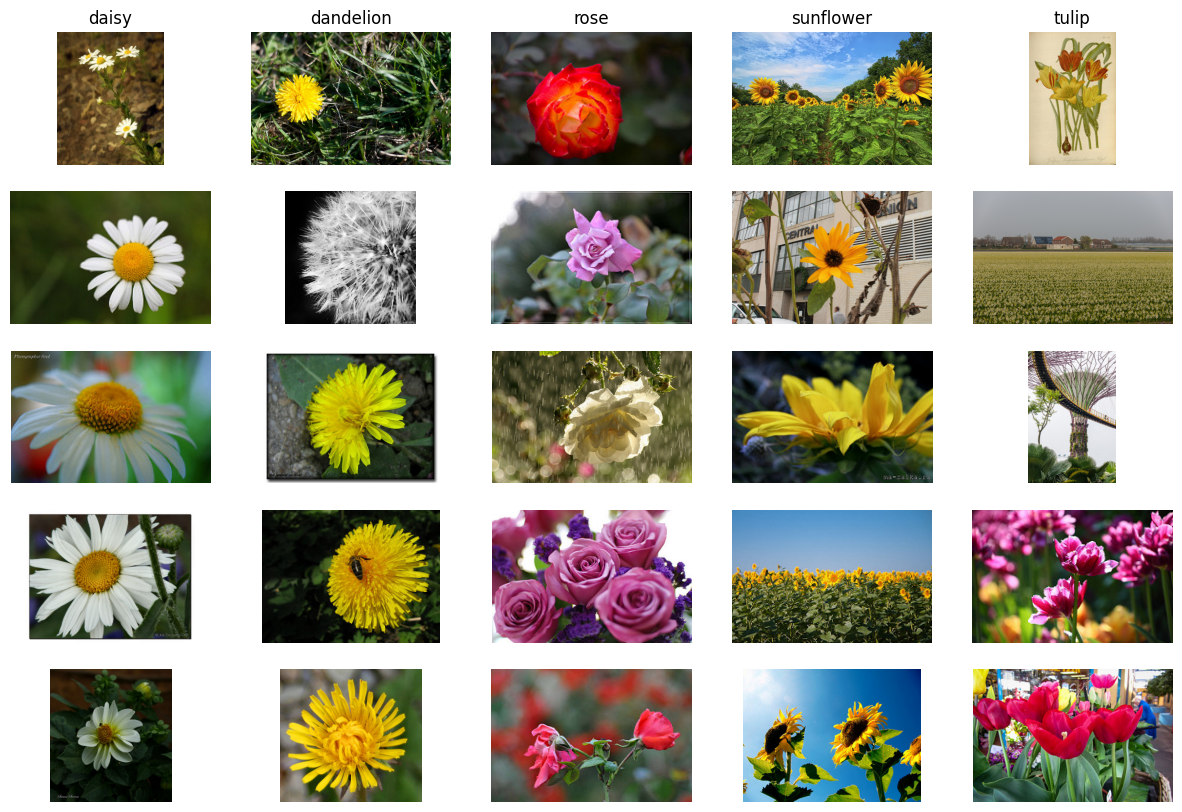

In [22]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=image_df, x='Label')
plt.title('Class Distribution')
plt.show()

# Display sample images from each class
def display_samples(df, n=5):
    fig, axes = plt.subplots(nrows=n, ncols=len(df['Label'].unique()), figsize=(15, 10))
    for i, label in enumerate(df['Label'].unique()):
        sample_images = df[df['Label'] == label].sample(n)
        for j, filepath in enumerate(sample_images['Filepath']):
            img = plt.imread(filepath)
            axes[j, i].imshow(img)
            axes[j, i].axis('off')
            if j == 0:
                axes[j, i].set_title(label)

display_samples(image_df)


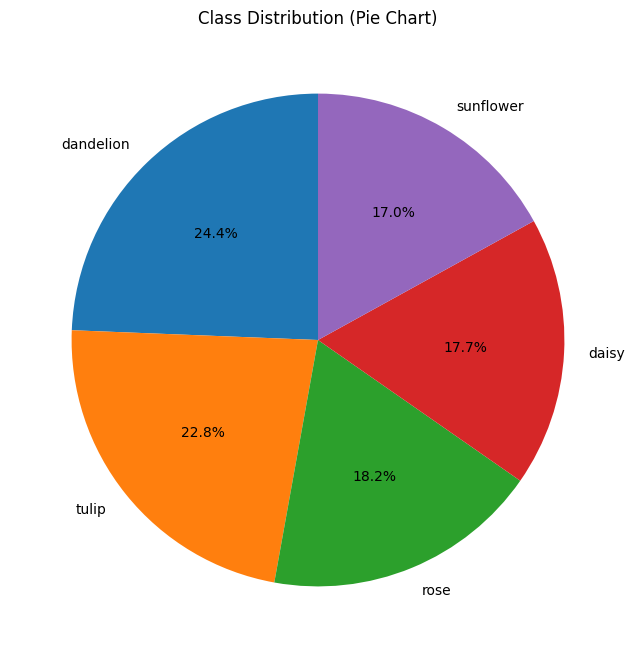

In [65]:
class_counts = image_df['Label'].value_counts()

# Pie chart of class distribution
plt.figure(figsize=(8, 8))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Class Distribution (Pie Chart)')
plt.show()

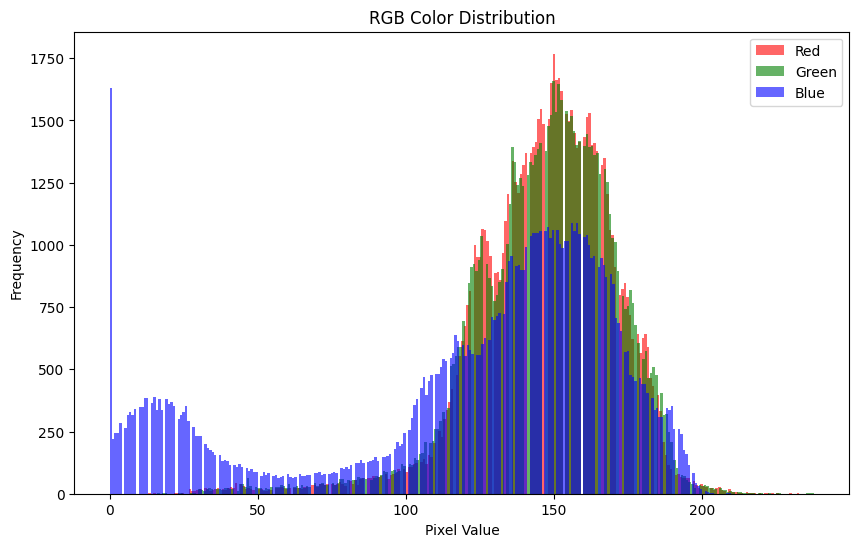

In [ ]:
def plot_rgb_histogram(image_path):
    img = plt.imread(image_path)
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    
    plt.figure(figsize=(10, 6))
    plt.hist(r.flatten(), bins=256, color='red', alpha=0.6, label='Red')
    plt.hist(g.flatten(), bins=256, color='green', alpha=0.6, label='Green')
    plt.hist(b.flatten(), bins=256, color='blue', alpha=0.6, label='Blue')
    plt.legend()
    plt.title('RGB Color Distribution')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.show()

plot_rgb_histogram(image_df['Filepath'].iloc[0])  


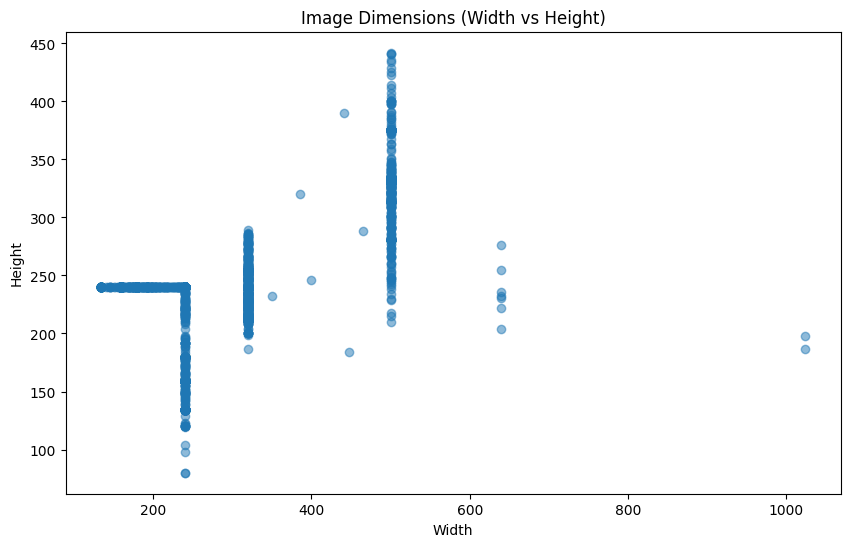

In [ ]:
# Get image dimensions
image_sizes = image_df['Filepath'].apply(lambda x: plt.imread(x).shape[:2])  
heights = image_sizes.apply(lambda x: x[0])
widths = image_sizes.apply(lambda x: x[1])

plt.figure(figsize=(10, 6))
plt.scatter(widths, heights, alpha=0.5)
plt.title('Image Dimensions (Width vs Height)')
plt.xlabel('Width')
plt.ylabel('Height')
plt.show()


## Data Preparation

In [23]:
train_df, test_df = train_test_split(image_df, train_size=0.8, shuffle=True, random_state=1)

In [24]:
train_df.shape

(3453, 2)

### *Data Augmentation*

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB1, ResNet50

train_generator = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,  
    rotation_range=30,              
    width_shift_range=0.2,          
    height_shift_range=0.2,
    shear_range=0.2,                
    zoom_range=0.2,                 
    horizontal_flip=True,           
    fill_mode='nearest',            
    validation_split=0.1            
)

test_generator = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input  
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..

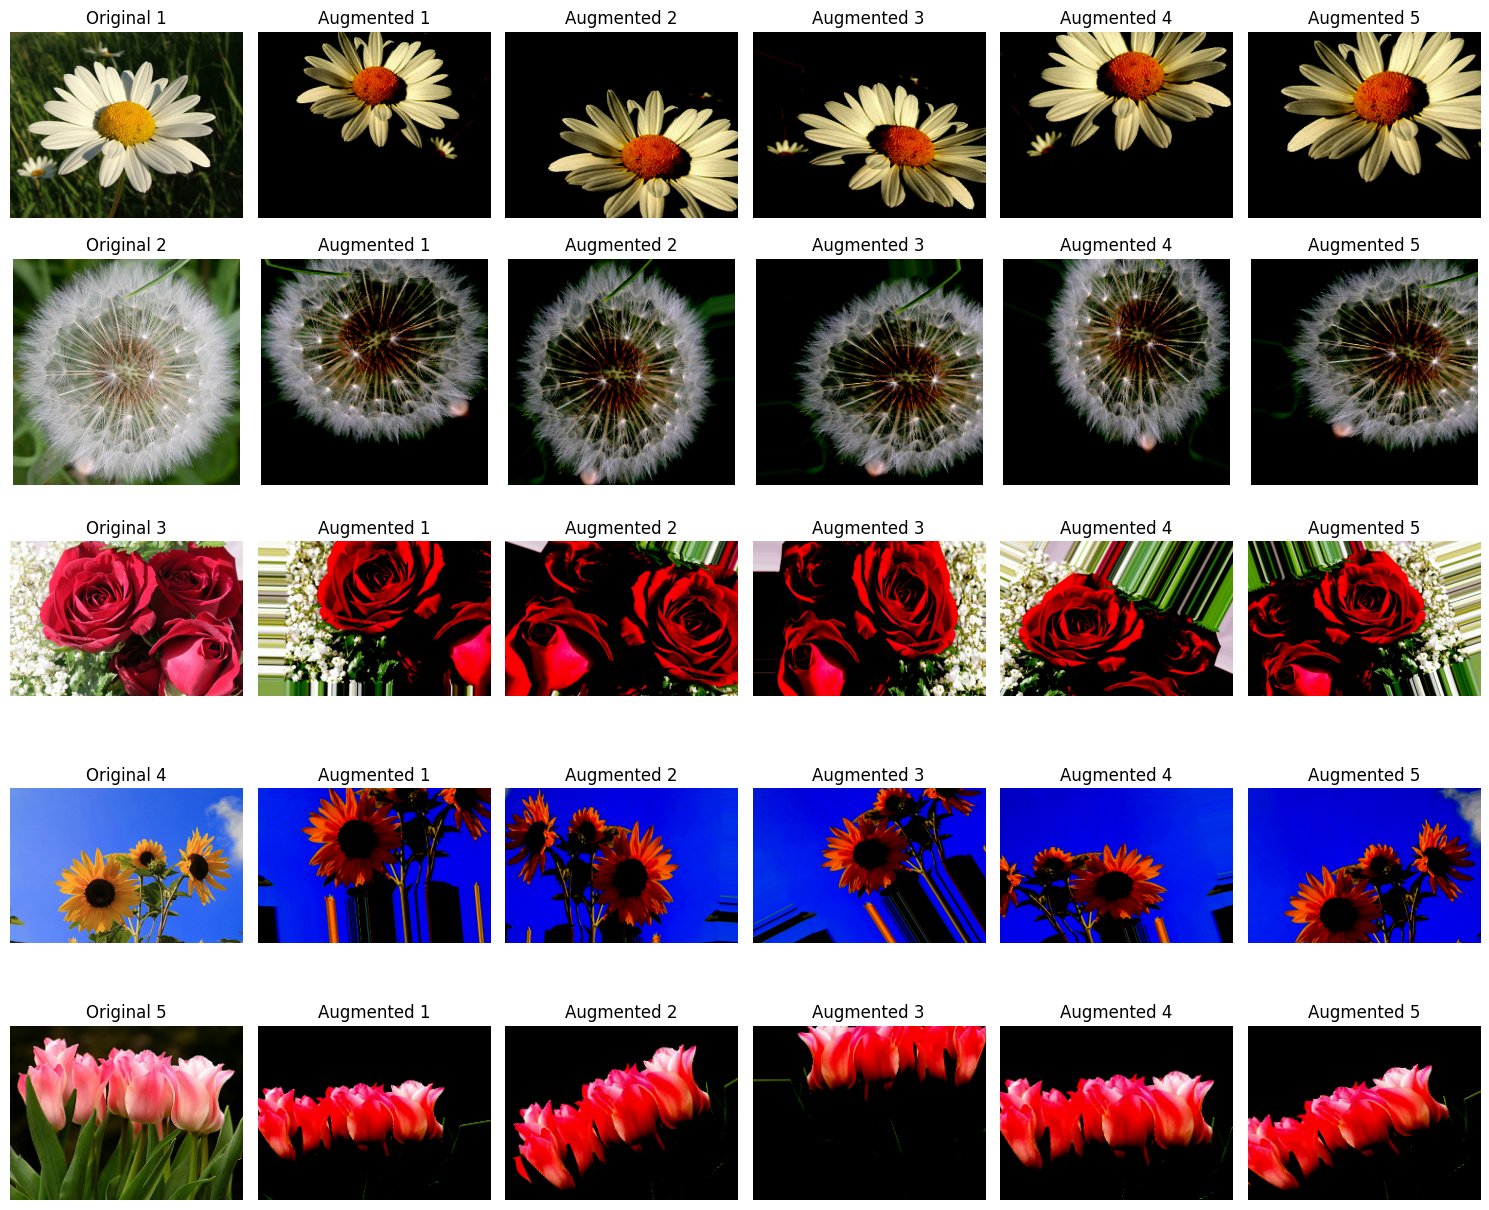

In [ ]:
original_image_paths = [
    './flowers/daisy/162362896_99c7d851c8_n.jpg',  
    './flowers/dandelion/13920113_f03e867ea7_m.jpg', 
    './flowers/rose/568715474_bdb64ccc32.jpg',
    './flowers/sunflower/1043442695_4556c4c13d_n.jpg',
    './flowers/tulip/112651128_7b5d39a346_m.jpg'
]

# Function to display the original image and augmented images below it
def display_images(generator, original_images, n=5):
    rows = len(original_images)  
    fig, axes = plt.subplots(rows, n + 1, figsize=(15, 2.5 * rows))  

    for i, img_path in enumerate(original_images):
        original_image = plt.imread(img_path)  
        axes[i, 0].imshow(original_image)  
        axes[i, 0].axis('off')
        axes[i, 0].set_title(f"Original {i+1}")

        augmented_gen = generator.flow(original_image.reshape((1, *original_image.shape)), batch_size=1)

        for j in range(n):
            batch = next(augmented_gen)
            axes[i, j + 1].imshow(batch[0])  
            axes[i, j + 1].axis('off')
            axes[i, j + 1].set_title(f"Augmented {j+1}")

    plt.tight_layout()
    plt.show()

display_images(train_generator, original_image_paths, n=5)

## Training Models

In [ ]:
train_images = train_generator.flow_from_dataframe(
    dataframe=train_df,
    x_col='Filepath',
    y_col='Label',
    target_size=(224, 224),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    seed=42,
    subset='training'  
)

val_images = train_generator.flow_from_dataframe(
    dataframe=train_df,
    x_col='Filepath',
    y_col='Label',
    target_size=(224, 224),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    seed=42,
    subset='validation' 
)

test_images = test_generator.flow_from_dataframe(
    dataframe=test_df,
    x_col='Filepath',
    y_col='Label',
    target_size=(224, 224),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

Found 3108 validated image filenames belonging to 5 classes.
Found 345 validated image filenames belonging to 5 classes.
Found 864 validated image filenames belonging to 5 classes.


In [ ]:
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

def create_model(base_model_fn, input_shape=(224, 224, 3), dropout_rate=0.1, dense_units=56):
    inputs = Input(shape=input_shape)
    base_model = base_model_fn(include_top=False, weights='imagenet', input_shape=input_shape)
    x = base_model(inputs)
    x = GlobalAveragePooling2D()(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(5, activation='sigmoid')(x)
    return Model(inputs, outputs)

In [ ]:
import os
import tensorflow.keras.backend as K
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def compile_and_train(model, name):
    K.clear_session()
    model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy', 'AUC'])
    
    checkpoint_path = f'models/{name}/model_224.keras'
    
    if os.path.exists(checkpoint_path):
        model.load_weights(checkpoint_path)
    
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=15, verbose=1, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=2, min_lr=1e-6, verbose=1),
        ModelCheckpoint(filepath=checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1)
    ]
    
    return model.fit(
        train_images,
        validation_data=val_images,
        epochs=30,  
        steps_per_epoch=train_images.samples // train_images.batch_size,
        validation_steps=val_images.samples // val_images.batch_size,
        callbacks=callbacks,
        verbose=1
    )

### MobileNet

In [40]:
mob_model = create_model(MobileNetV2)
mob_history = compile_and_train(mob_model, 'MobileNetV2')

Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - AUC: 0.9431 - accuracy: 0.8178 - loss: 0.5436
Epoch 1: val_loss improved from inf to 13.57617, saving model to models/MobileNetV2/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 87s 739ms/step - AUC: 0.9431 - accuracy: 0.8179 - loss: 0.5433 - val_AUC: 0.6384 - val_accuracy: 0.3031 - val_loss: 13.5762 - learning_rate: 0.0010
Epoch 2/30
 1/97 ━━━━━━━━━━━━━━━━━━━━ 1:10 739ms/step - AUC: 0.9658 - accuracy: 0.9062 - loss: 0.4785
Epoch 2: val_loss did not improve from 13.57617
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - AUC: 0.9658 - accuracy: 0.9062 - loss: 0.4785 - val_AUC: 0.6302 - val_accuracy: 0.2906 - val_loss: 14.4198 - learning_rate: 0.0010
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 791ms/step - AUC: 0.9572 - accuracy: 0.8449 - loss: 0.4459
Epoch 3: val_loss improved from 13.57617 to 5.58057, saving model to models/MobileNetV2/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 80s 826ms/step - AUC: 0.9572 - accuracy: 0.8449 - loss: 0.4459 - val_AU

In [ ]:
results = mob_model.evaluate(test_images, verbose=1)

test_loss = results[0]
test_accuracy = results[1]

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 200ms/step - AUC: 0.9859 - accuracy: 0.9216 - loss: 0.2834
Test Loss: 0.2940
Test Accuracy: 0.9201


In [ ]:
train_accuracy = mob_history.history['accuracy'][-1]  
val_accuracy = mob_history.history['val_accuracy'][-1]  

print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

Train Accuracy: 0.9375
Validation Accuracy: 0.8813


In [ ]:
from sklearn.metrics import classification_report

test_labels = test_images.labels  
test_predictions = mob_model.predict(test_images, verbose=1)  
mob_pred_labels = test_predictions.argmax(axis=1)  

class_names = list(test_images.class_indices.keys())

report = classification_report(test_labels, mob_pred_labels, target_names=class_names)
print("MobileNet - Classification Report:")
print(report)

27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 177ms/step
MobileNet - Classification Report:
              precision    recall  f1-score   support

       daisy       0.90      0.93      0.91       143
   dandelion       0.94      0.95      0.94       213
        rose       0.93      0.90      0.91       164
   sunflower       0.92      0.96      0.94       159
       tulip       0.91      0.87      0.89       185

    accuracy                           0.92       864
   macro avg       0.92      0.92      0.92       864
weighted avg       0.92      0.92      0.92       864



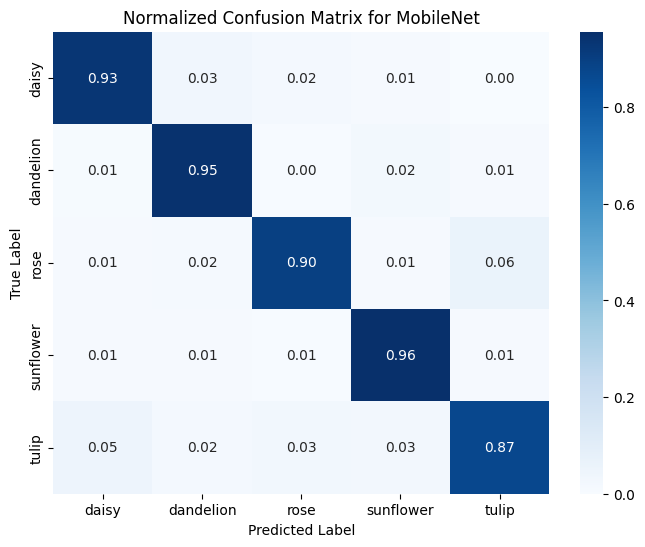

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

mob_cm = confusion_matrix(test_labels, mob_pred_labels, normalize='true')

class_names = list(test_images.class_indices.keys())

plt.figure(figsize=(8, 6))
sns.heatmap(mob_cm, annot=True, cmap='Blues', fmt='.2f', xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized Confusion Matrix for MobileNet')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step


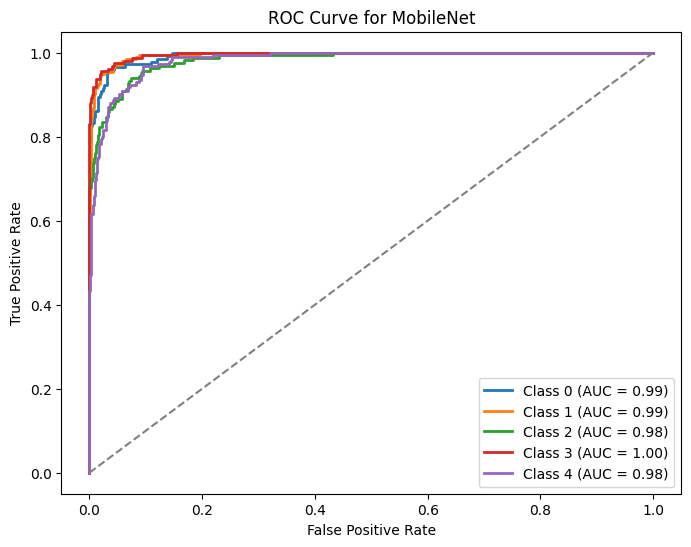

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

mob_predictions_prob = mob_model.predict(test_images, verbose=1)

test_labels_onehot = tf.keras.utils.to_categorical(test_labels, num_classes=5)

plt.figure(figsize=(8, 6))
n_classes = test_labels_onehot.shape[1]

for i in range(n_classes):

    fpr, tpr, thresholds = roc_curve(test_labels_onehot[:, i], mob_predictions_prob[:, i])
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for MobileNet')
plt.legend(loc='lower right')
plt.show()


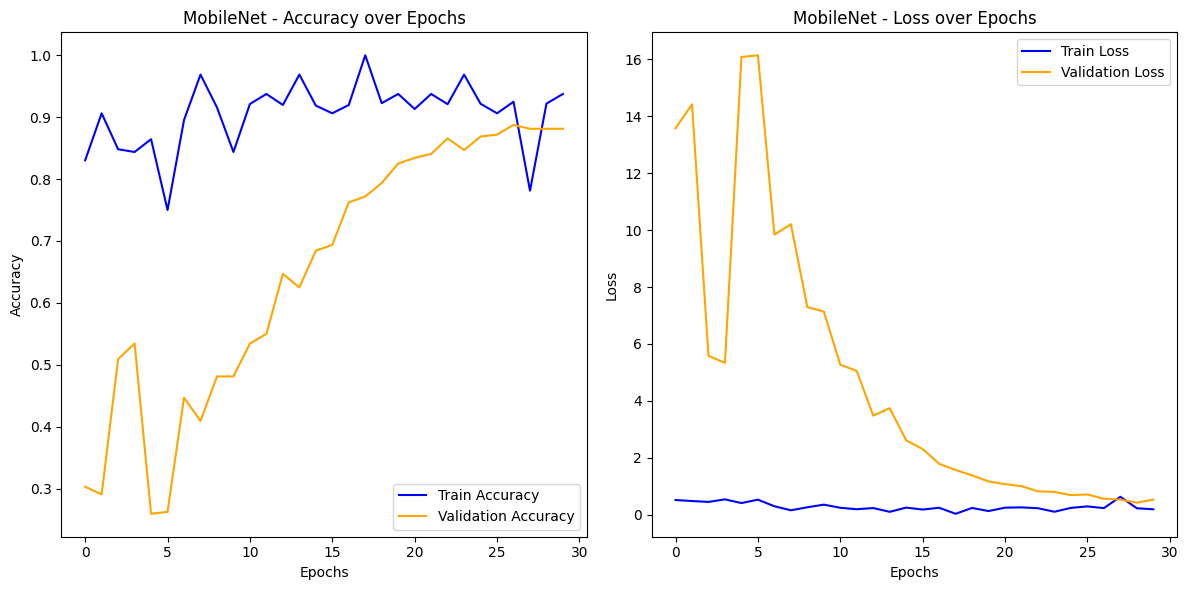

In [ ]:
history = mob_model.history.history  

# Accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('MobileNet - Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history['loss'], label='Train Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='orange')
plt.title('MobileNet - Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


### ResNet

In [45]:
resnet_model = create_model(ResNet50)
resnet_history = compile_and_train(resnet_model, 'ResNet50')

Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - AUC: 0.8269 - accuracy: 0.5986 - loss: 1.0835
Epoch 1: val_loss improved from inf to 470.18823, saving model to models/ResNet50/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - AUC: 0.8271 - accuracy: 0.5987 - loss: 1.0831 - val_AUC: 0.5258 - val_accuracy: 0.2062 - val_loss: 470.1882 - learning_rate: 0.0010
Epoch 2/30
 1/97 ━━━━━━━━━━━━━━━━━━━━ 3:45 2s/step - AUC: 0.8195 - accuracy: 0.6562 - loss: 0.9631
Epoch 2: val_loss did not improve from 470.18823
97/97 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - AUC: 0.8195 - accuracy: 0.6562 - loss: 0.9631 - val_AUC: 0.4766 - val_accuracy: 0.2000 - val_loss: 1009.6444 - learning_rate: 0.0010
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - AUC: 0.8640 - accuracy: 0.6678 - loss: 0.9010
Epoch 3: val_loss improved from 470.18823 to 3.16432, saving model to models/ResNet50/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - AUC: 0.8640 - accuracy: 0.6679 - loss: 0.9005 - val_AUC: 0.5458 - v

In [ ]:
resnet_results = resnet_model.evaluate(test_images, verbose=1)

resnet_test_loss = resnet_results[0]
resnet_test_accuracy = resnet_results[1]

print(f"ResNet - Test Loss: {resnet_test_loss:.4f}")
print(f"ResNet - Test Accuracy: {resnet_test_accuracy:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 607ms/step - AUC: 0.9674 - accuracy: 0.8724 - loss: 0.3528
ResNet - Test Loss: 0.3332
ResNet - Test Accuracy: 0.8762


In [ ]:
resnet_train_accuracy = resnet_history.history['accuracy'][-1]  
resnet_val_accuracy = resnet_history.history['val_accuracy'][-1]  

print(f"ResNet - Train Accuracy: {resnet_train_accuracy:.4f}")
print(f"ResNet - Validation Accuracy: {resnet_val_accuracy:.4f}")

ResNet - Train Accuracy: 0.8438
ResNet - Validation Accuracy: 0.8938


In [ ]:
from sklearn.metrics import classification_report

resnet_test_labels = test_images.labels  # True labels
resnet_predictions = resnet_model.predict(test_images, verbose=1)  
resnet_pred_labels = resnet_predictions.argmax(axis=1)  

class_names = list(test_images.class_indices.keys())

resnet_report = classification_report(resnet_test_labels, resnet_pred_labels, target_names=class_names)
print("ResNet - Classification Report:")
print(resnet_report)

27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 515ms/step
ResNet - Classification Report:
              precision    recall  f1-score   support

       daisy       0.94      0.89      0.91       143
   dandelion       0.93      0.87      0.90       213
        rose       0.83      0.84      0.83       164
   sunflower       0.85      0.94      0.89       159
       tulip       0.84      0.85      0.84       185

    accuracy                           0.88       864
   macro avg       0.88      0.88      0.88       864
weighted avg       0.88      0.88      0.88       864



27/27 ━━━━━━━━━━━━━━━━━━━━ 14s 511ms/step


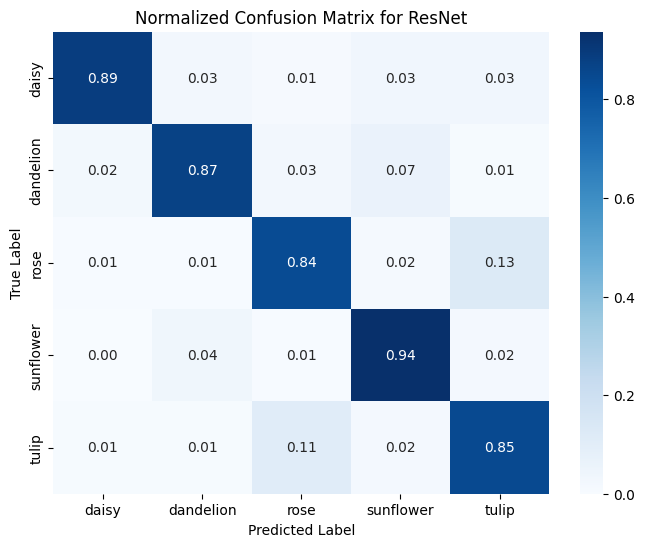

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

resnet_predictions = resnet_model.predict(test_images, verbose=1)  
resnet_pred_labels = resnet_predictions.argmax(axis=1)  

resnet_cm = confusion_matrix(test_labels, resnet_pred_labels, normalize='true')

class_names = list(test_images.class_indices.keys())

plt.figure(figsize=(8, 6))
sns.heatmap(resnet_cm, annot=True, cmap='Blues', fmt='.2f', xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized Confusion Matrix for ResNet')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


27/27 ━━━━━━━━━━━━━━━━━━━━ 12s 454ms/step


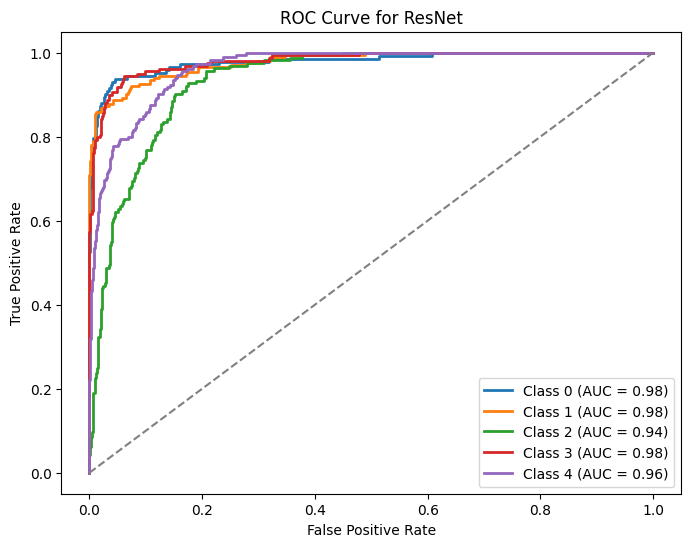

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

resnet_predictions_prob = resnet_model.predict(test_images, verbose=1)

test_labels_onehot = tf.keras.utils.to_categorical(test_labels, num_classes=5)

plt.figure(figsize=(8, 6))
n_classes = test_labels_onehot.shape[1]

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(test_labels_onehot[:, i], resnet_predictions_prob[:, i])
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for ResNet')
plt.legend(loc='lower right')
plt.show()


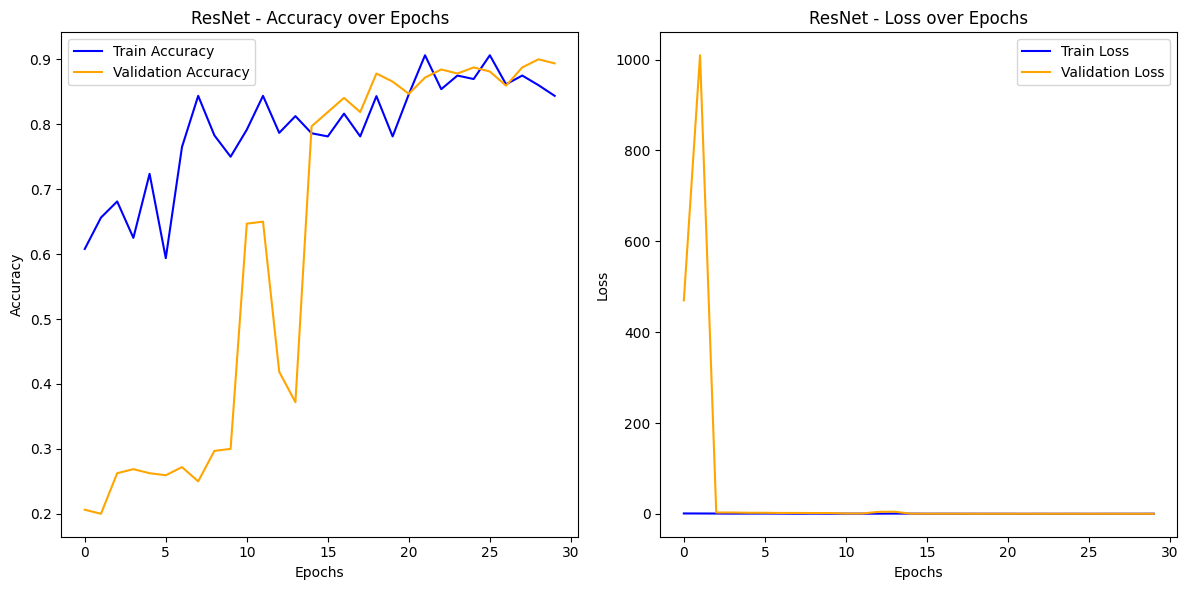

In [ ]:
history = resnet_model.history.history  

# Accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('ResNet - Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history['loss'], label='Train Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='orange')
plt.title('ResNet - Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


### Inception

In [ ]:
from tensorflow.keras.applications import InceptionV3

inception_model = create_model(InceptionV3)

inception_history = compile_and_train(inception_model, 'InceptionV3')

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 22s 0us/step
Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - AUC: 0.8492 - accuracy: 0.6428 - loss: 1.0033
Epoch 1: val_loss improved from inf to 33.03509, saving model to models/InceptionV3/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 343s 3s/step - AUC: 0.8494 - accuracy: 0.6433 - loss: 1.0022 - val_AUC: 0.5702 - val_accuracy: 0.2406 - val_loss: 33.0351 - learning_rate: 0.0010
Epoch 2/30
 1/97 ━━━━━━━━━━━━━━━━━━━━ 4:00 3s/step - AUC: 0.9344 - accuracy: 0.8438 - loss: 0.5883
Epoch 2: val_loss improved from 33.03509 to 21.30424, saving model to models/InceptionV3/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 17s 153ms/step - AUC: 0.9344 - accuracy: 0.8438 - loss: 0.5883 - val_AUC: 0.6021 - val_accuracy: 0.3063 - val_loss: 21.3042 - learning_rate: 0.0010
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - AUC: 0.9165 - accuracy: 0.7830 - loss: 0.6679
Epoch 3: val_loss improved from 21.30424 to 3.57567, saving model to models/InceptionV3/model_224.kera

In [ ]:
inception_results = inception_model.evaluate(test_images, verbose=1)

inception_test_loss = inception_results[0]
inception_test_accuracy = inception_results[1]

print(f"InceptionV3 - Test Loss: {inception_test_loss:.4f}")
print(f"InceptionV3 - Test Accuracy: {inception_test_accuracy:.4f}")


27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 301ms/step - AUC: 0.9844 - accuracy: 0.9108 - loss: 0.2458
InceptionV3 - Test Loss: 0.2330
InceptionV3 - Test Accuracy: 0.9155


In [ ]:

inception_train_accuracy = inception_history.history['accuracy'][-1]  
inception_val_accuracy = inception_history.history['val_accuracy'][-1]  

print(f"InceptionV3 - Train Accuracy: {inception_train_accuracy:.4f}")
print(f"InceptionV3 - Validation Accuracy: {inception_val_accuracy:.4f}")

InceptionV3 - Train Accuracy: 0.9375
InceptionV3 - Validation Accuracy: 0.8875


In [ ]:
from sklearn.metrics import classification_report

inception_test_labels = test_images.labels  
inception_predictions = inception_model.predict(test_images, verbose=1)  
inception_pred_labels = inception_predictions.argmax(axis=1) 

class_names = list(test_images.class_indices.keys())

inception_report = classification_report(inception_test_labels, inception_pred_labels, target_names=class_names)
print("InceptionV3 - Classification Report:")
print(inception_report)


27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 320ms/step
InceptionV3 - Classification Report:
              precision    recall  f1-score   support

       daisy       0.99      0.92      0.95       143
   dandelion       0.97      0.92      0.94       213
        rose       0.88      0.90      0.89       164
   sunflower       0.91      0.94      0.92       159
       tulip       0.85      0.91      0.88       185

    accuracy                           0.92       864
   macro avg       0.92      0.92      0.92       864
weighted avg       0.92      0.92      0.92       864



27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 304ms/step


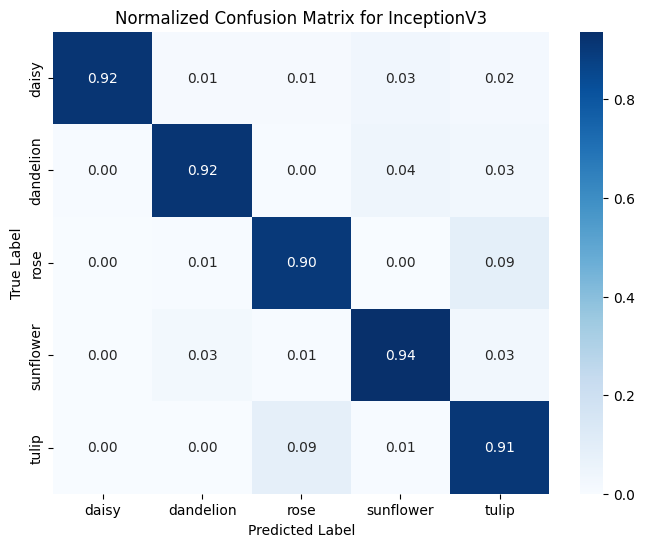

In [ ]:
inception_predictions = inception_model.predict(test_images, verbose=1)  
inception_pred_labels = inception_predictions.argmax(axis=1) 

inception_cm = confusion_matrix(test_labels, inception_pred_labels, normalize='true')

plt.figure(figsize=(8, 6))
sns.heatmap(inception_cm, annot=True, cmap='Blues', fmt='.2f', xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized Confusion Matrix for InceptionV3')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 278ms/step


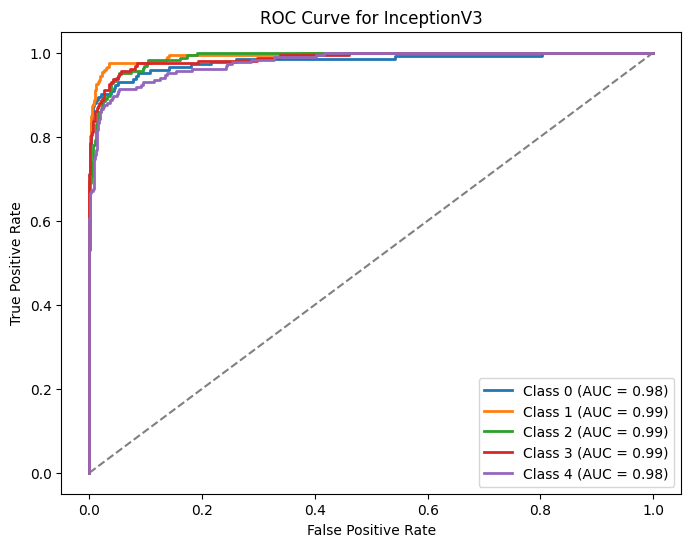

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

inception_predictions_prob = inception_model.predict(test_images, verbose=1)

test_labels_onehot = tf.keras.utils.to_categorical(test_labels, num_classes=5)

plt.figure(figsize=(8, 6))
n_classes = test_labels_onehot.shape[1]

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(test_labels_onehot[:, i], inception_predictions_prob[:, i])
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for InceptionV3')
plt.legend(loc='lower right')
plt.show()


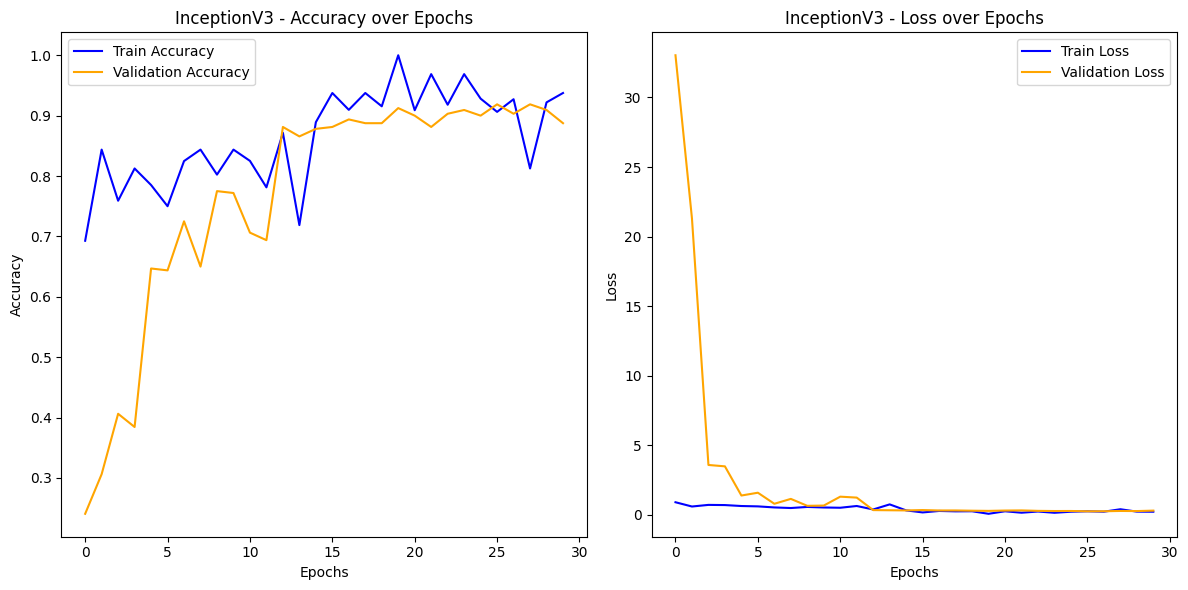

In [ ]:

history = inception_model.history.history  

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('InceptionV3 - Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['loss'], label='Train Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='orange')
plt.title('InceptionV3 - Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


### EfficientNet

In [54]:
eff_model = create_model(EfficientNetB1)
eff_history = compile_and_train(eff_model, 'EfficientNetB1')

Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - AUC: 0.9707 - accuracy: 0.9039 - loss: 0.2879
Epoch 1: val_loss improved from inf to 2.60954, saving model to models/EfficientNetB1/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 335s 2s/step - AUC: 0.9707 - accuracy: 0.9039 - loss: 0.2881 - val_AUC: 0.5550 - val_accuracy: 0.2500 - val_loss: 2.6095 - learning_rate: 0.0010
Epoch 2/30
 1/97 ━━━━━━━━━━━━━━━━━━━━ 3:05 2s/step - AUC: 0.9796 - accuracy: 0.8750 - loss: 0.2264
Epoch 2: val_loss did not improve from 2.60954
97/97 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - AUC: 0.9796 - accuracy: 0.8750 - loss: 0.2264 - val_AUC: 0.5474 - val_accuracy: 0.2500 - val_loss: 2.6332 - learning_rate: 0.0010
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - AUC: 0.9770 - accuracy: 0.9209 - loss: 0.2512
Epoch 3: val_loss improved from 2.60954 to 2.55471, saving model to models/EfficientNetB1/model_224.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 194s 2s/step - AUC: 0.9770 - accuracy: 0.9209 - loss: 0.2512 - val_AUC: 0.6023 - 

In [ ]:

eff_results = eff_model.evaluate(test_images, verbose=1)

eff_test_loss = eff_results[0]
eff_test_accuracy = eff_results[1]

print(f"EfficientNetB1 - Test Loss: {eff_test_loss:.4f}")
print(f"EfficientNetB1 - Test Accuracy: {eff_test_accuracy:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 12s 459ms/step - AUC: 0.9895 - accuracy: 0.9849 - loss: 0.0493
EfficientNetB1 - Test Loss: 0.0521
EfficientNetB1 - Test Accuracy: 0.9850


In [ ]:

eff_train_accuracy = eff_history.history['accuracy'][-1] 
eff_val_accuracy = eff_history.history['val_accuracy'][-1]  

print(f"EfficientNetB1 - Train Accuracy: {eff_train_accuracy:.4f}")
print(f"EfficientNetB1 - Validation Accuracy: {eff_val_accuracy:.4f}")

EfficientNetB1 - Train Accuracy: 0.9688
EfficientNetB1 - Validation Accuracy: 0.9656


In [ ]:
from sklearn.metrics import classification_report

eff_test_labels = test_images.labels  
eff_predictions = eff_model.predict(test_images, verbose=1)  
eff_pred_labels = eff_predictions.argmax(axis=1)  

class_names = list(test_images.class_indices.keys())

eff_report = classification_report(eff_test_labels, eff_pred_labels, target_names=class_names)
print("EfficientNetB1 - Classification Report:")
print(eff_report)

27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 306ms/step
EfficientNetB1 - Classification Report:
              precision    recall  f1-score   support

       daisy       0.99      0.97      0.98       143
   dandelion       0.97      1.00      0.99       213
        rose       1.00      0.98      0.99       164
   sunflower       0.99      0.97      0.98       159
       tulip       0.97      1.00      0.99       185

    accuracy                           0.98       864
   macro avg       0.99      0.98      0.98       864
weighted avg       0.99      0.98      0.98       864



27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 302ms/step


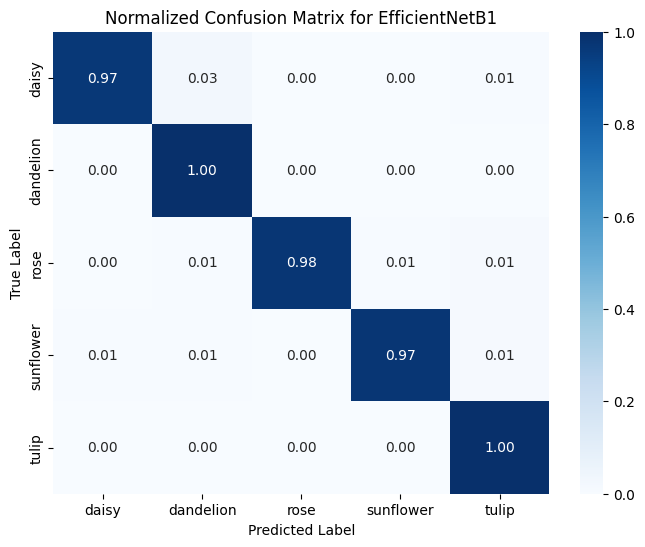

In [ ]:

eff_predictions = eff_model.predict(test_images, verbose=1)  
eff_pred_labels = eff_predictions.argmax(axis=1)  

eff_cm = confusion_matrix(test_labels, eff_pred_labels, normalize='true')

plt.figure(figsize=(8, 6))
sns.heatmap(eff_cm, annot=True, cmap='Blues', fmt='.2f', xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized Confusion Matrix for EfficientNetB1')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 276ms/step


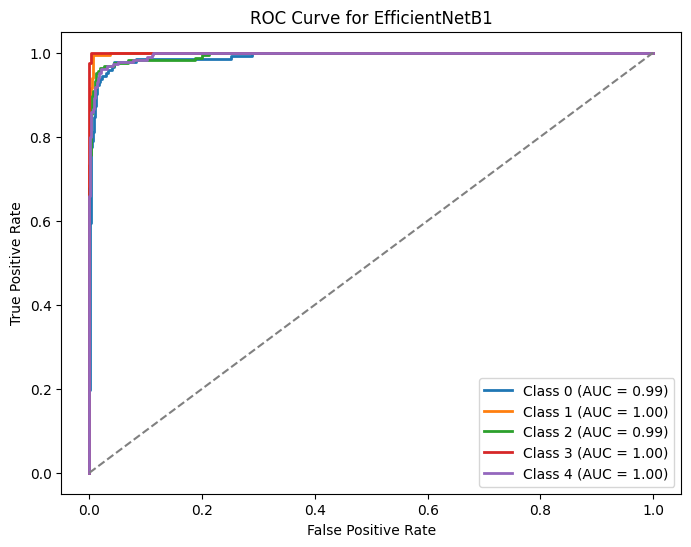

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

eff_predictions_prob = eff_model.predict(test_images, verbose=1)

test_labels_onehot = tf.keras.utils.to_categorical(test_labels, num_classes=5)

plt.figure(figsize=(8, 6))
n_classes = test_labels_onehot.shape[1]

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(test_labels_onehot[:, i], eff_predictions_prob[:, i])
    roc_auc = auc(fpr, tpr)
    
    # Plot ROC curve for this class
    plt.plot(fpr, tpr, lw=2, label=f'Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for EfficientNetB1')
plt.legend(loc='lower right')
plt.show()


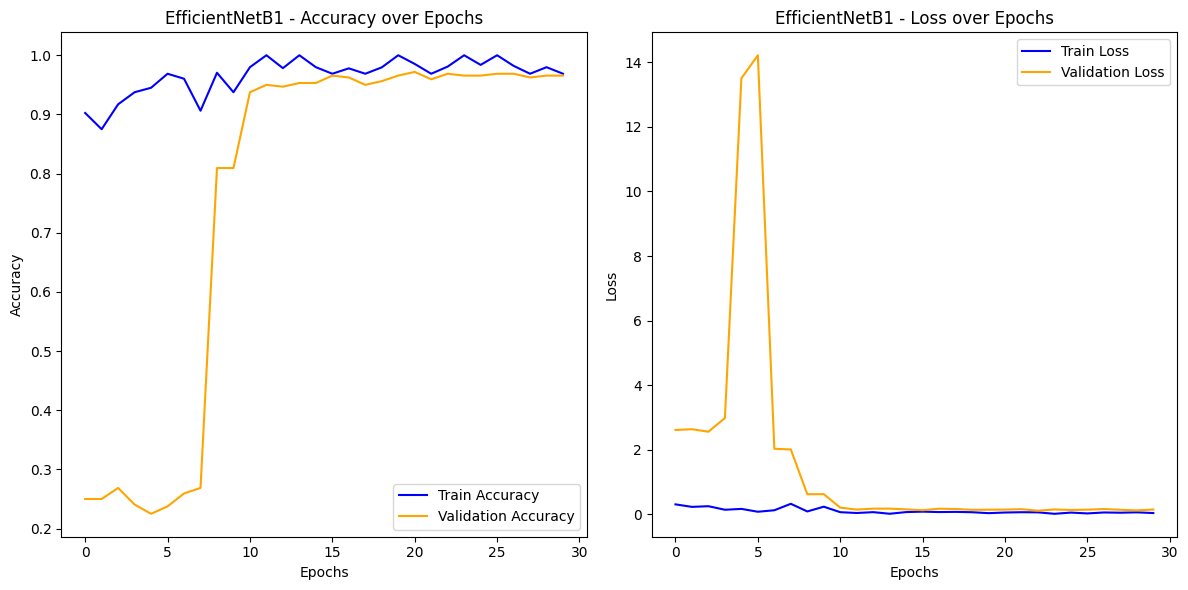

In [ ]:

history = eff_model.history.history 

# Accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('EfficientNetB1 - Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history['loss'], label='Train Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='orange')
plt.title('EfficientNetB1 - Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


## Evaluation (Comparision)

In [ ]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Model': ['MobileNet', 'ResNet', 'InceptionV3', 'EfficientNetB1'],
    'Test Accuracy': [mob_test_accuracy, resnet_test_accuracy, inception_test_accuracy, eff_test_accuracy]
})

# Print the comparison table
print(model_comparison)

# Find the model with the highest test accuracy
best_model = model_comparison.loc[model_comparison['Test Accuracy'].idxmax()]

# Print the model with the highest accuracy
print(f"The model with the highest test accuracy is {best_model['Model']} with an accuracy of {best_model['Test Accuracy']:.4f}.")


            Model  Test Accuracy
0       MobileNet       0.920139
1          ResNet       0.876157
2     InceptionV3       0.915509
3  EfficientNetB1       0.984954
The model with the highest test accuracy is EfficientNetB1 with an accuracy of 0.9850.


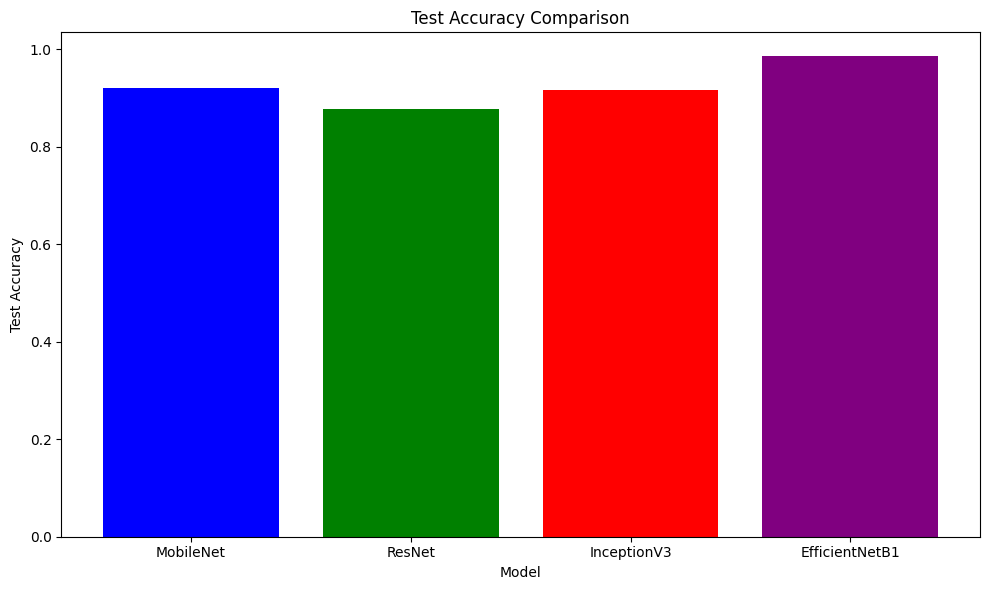

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(model_comparison['Model'], model_comparison['Test Accuracy'], color=['blue', 'green', 'red', 'purple'])

plt.title('Test Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')

plt.tight_layout()
plt.show()

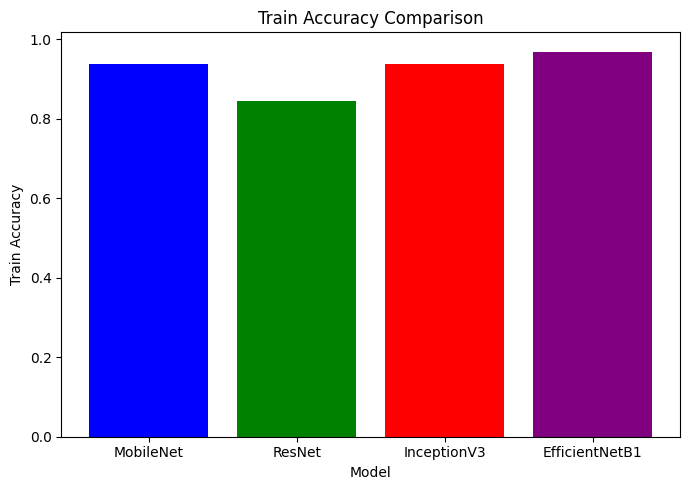

In [ ]:

plt.figure(figsize=(7, 5))
plt.bar(model_comparison['Model'], model_comparison['Train Accuracy'], color=['blue', 'green', 'red', 'purple'])
plt.title('Train Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Train Accuracy')
plt.tight_layout()
plt.show()


## Saving Test Images 

In [ ]:
import os
import shutil

destination_root = 'test_images'
os.makedirs(destination_root, exist_ok=True)

for filepath, label in zip(test_df['Filepath'], test_df['Label']):
    label_folder = os.path.join(destination_root, str(label))
    os.makedirs(label_folder, exist_ok=True)
    shutil.copy(filepath, os.path.join(label_folder, os.path.basename(filepath)))

In [88]:
import json

with open('models/EfficientNetB1/class_indices.json', 'w') as f:
    json.dump(train_images.class_indices, f)